# Ejercicio 1: Predicción del precio del dólar

**Laboratorio 1 – Minería de Datos** · Regresión lineal múltiple siguiendo la metodología **CRISP-DM**

Dataset: `data/dolar_data.csv` · Variable dependiente: `Precio_Dolar`

**Contenido**
1. Comprensión del negocio
2. Comprensión de los datos (EDA)
3. Preparación de los datos
4. Modelado
5. Evaluación
6. Despliegue: exportación del modelo
7. Conclusiones

## 1. Comprensión del negocio

**Contexto.** El precio del dólar influye en las importaciones, las deudas en moneda extranjera y los precios de muchos productos. Poder anticiparlo ayuda a planear compras y presupuestos.

**Objetivo de minería de datos.** Construir un modelo de **regresión lineal múltiple** que prediga `Precio_Dolar` a partir de:

| Variable | Descripción | Rol |
|---|---|---|
| `Dia` | Número de día (1, 2, 3, ...) | Independiente |
| `Inflacion` | Tasa de inflación diaria | Independiente |
| `Tasa_interes` | Tasa de interés diaria | Independiente |
| `Precio_Dolar` | Precio del dólar | **Dependiente** |

**Preguntas a responder.**
1. ¿Cómo afecta cada variable al precio del dólar? (interpretación de coeficientes)
2. ¿Qué tan bien predice el modelo? (MSE y R²)
3. ¿Cómo se ve la relación de cada variable con el precio? (gráficas)

**Criterio de éxito.** Un R² alto en datos de prueba y un error pequeño comparado con el precio promedio.

### Librerías y configuración

In [1]:
import json
import pickle
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels.api as sm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Rutas del proyecto (funciona ejecutando desde notebooks/ o desde la raíz)
BASE = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = BASE / "data"
FIGURAS = BASE / "informe" / "figuras"
MODELOS = BASE / "modelos"
FIGURAS.mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(parents=True, exist_ok=True)

# Configuración del ejercicio
NOMBRE = "dolar"
OBJETIVO = "Precio_Dolar"
VARIABLES = ['Dia', 'Inflacion', 'Tasa_interes']
ETIQUETAS = {'Dia': 'Día (número de día)', 'Inflacion': 'Inflación diaria (proporción)', 'Tasa_interes': 'Tasa de interés diaria (%)', 'Precio_Dolar': 'Precio del dólar (pesos)'}
UNIDAD_Y = "pesos"
SEMILLA = 42

# Estilo de las gráficas
AZUL, NARANJA, AQUA, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
TEXTO, TEXTO_SEC, REJILLA = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TEXTO_SEC,
    "axes.titlecolor": TEXTO, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TEXTO_SEC, "ytick.color": TEXTO_SEC,
    "legend.frameon": False, "font.size": 10, "savefig.dpi": 150,
})
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list("azul_rojo", [AZUL, "#f0efec", ROJO])


def guardar(fig, nombre):
    """Guarda la figura como PNG en informe/figuras/."""
    ruta = FIGURAS / f"{NOMBRE}_{nombre}.png"
    fig.savefig(ruta, bbox_inches="tight")
    print("Figura guardada:", ruta.relative_to(BASE))


def fmt_p(p):
    """Muestra un p-valor de forma legible."""
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 2. Comprensión de los datos (EDA)

### 2.1 Carga y estructura

In [2]:
df = pd.read_csv(DATA / f"{NOMBRE}_data.csv")
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (500, 4)


,Dia,Inflacion,Tasa_interes,Precio_Dolar
0,1,0.0225,5.4631,"4,024.8336"
1,2,0.0193,5.9547,"4,000.5463"
2,3,0.0232,4.3007,"3,979.6220"
3,4,0.0276,5.2815,"3,940.3613"
4,5,0.0188,4.6747,"4,016.9302"


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Dia           500 non-null    int64  
 1   Inflacion     500 non-null    float64
 2   Tasa_interes  500 non-null    float64
 3   Precio_Dolar  500 non-null    float64
dtypes: float64(3), int64(1)
memory usage: 15.8 KB


### 2.2 Estadísticas descriptivas y rangos

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Dia,500.0000,250.5000,144.4818,1.0000,125.7500,250.5000,375.2500,500.0000
Inflacion,500.0000,0.0200,0.0049,0.0038,0.0165,0.0201,0.0232,0.0393
Tasa_interes,500.0000,5.0159,0.4890,3.6516,4.7024,5.0143,5.3256,6.3162
Precio_Dolar,500.0000,"5,211.7719",723.8952,"3,940.3613","4,604.8850","5,218.7911","5,825.2353","6,553.5986"


### 2.3 Calidad de los datos: nulos, duplicados y atípicos

In [5]:
print("Valores nulos por columna:")
print(df.isna().sum().to_string())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores nulos por columna:
Dia             0
Inflacion       0
Tasa_interes    0
Precio_Dolar    0

Filas duplicadas: 0


In [6]:
# Valores atípicos con la regla del rango intercuartílico (IQR)
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = ((df < lim_inf) | (df > lim_sup)).sum()
pd.DataFrame({
    "limite_inferior": lim_inf, "limite_superior": lim_sup,
    "minimo": df.min(), "maximo": df.max(),
    "n_atipicos": atipicos, "porcentaje": 100 * atipicos / len(df),
})

,limite_inferior,limite_superior,minimo,maximo,n_atipicos,porcentaje
Dia,-248.5000,749.5000,1.0000,500.0000,0,0.0000
Inflacion,0.0065,0.0332,0.0038,0.0393,4,0.8000
Tasa_interes,3.7675,6.2605,3.6516,6.3162,7,1.4000
Precio_Dolar,"2,774.3595","7,655.7608","3,940.3613","6,553.5986",0,0.0000


**Hallazgos de la revisión de calidad**

- El dataset tiene **500 filas y 4 columnas**, todas numéricas. `Dia` es un entero consecutivo de 1 a 500.
- **No hay valores nulos ni filas duplicadas.**
- Con la regla IQR aparecen **4 valores atípicos en `Inflacion` y 7 en `Tasa_interes`**; `Dia` y `Precio_Dolar` no tienen ninguno. Son valores extremos pero posibles (inflación entre 0.0038 y 0.0393; tasa entre 3.65 y 6.32), no errores de digitación, y representan menos del 2 % de los datos. **Se conservan** para no perder información real.
- El precio va de 3 940 a 6 554 pesos, con media de 5 212.

### 2.4 Distribución de las variables

Figura guardada: informe/figuras/dolar_distribuciones.png


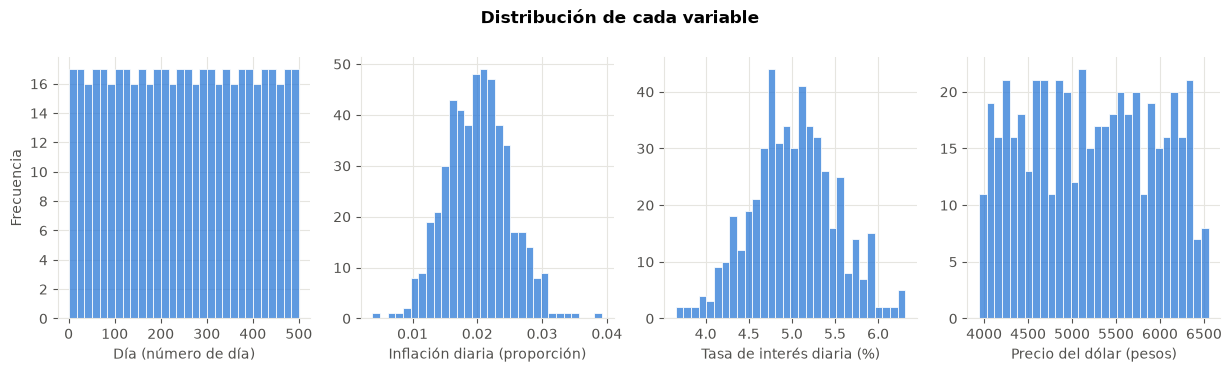

In [7]:
fig, ejes = plt.subplots(1, len(df.columns), figsize=(15, 3.4))
for ax, col in zip(ejes, df.columns):
    discreta = df[col].nunique() < 30
    sns.histplot(df[col], ax=ax, color=AZUL, edgecolor="white", discrete=discreta, bins="auto" if discreta else 30)
    ax.set_xlabel(ETIQUETAS[col])
    ax.set_ylabel("Frecuencia" if ax is ejes[0] else "")
fig.suptitle("Distribución de cada variable", fontweight="bold", y=1.02)
guardar(fig, "distribuciones")
plt.show()

### 2.5 Matriz de correlación

Figura guardada: informe/figuras/dolar_correlacion.png


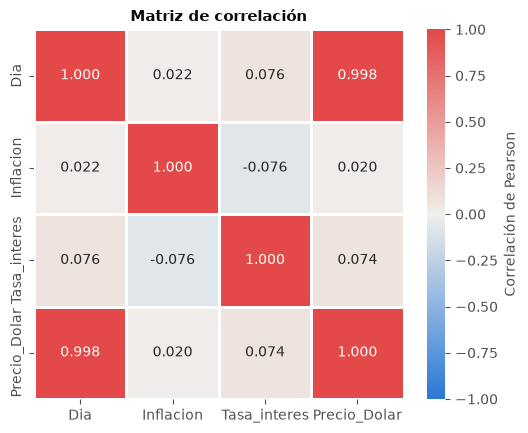

,Correlación con Precio_Dolar
Dia,0.9976
Inflacion,0.0196
Tasa_interes,0.0743


In [8]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(corr, annot=True, fmt=".3f", cmap=CMAP_DIVERGENTE, vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", square=True, ax=ax,
            cbar_kws={"label": "Correlación de Pearson"})
ax.set_title("Matriz de correlación")
ax.grid(False)
guardar(fig, "correlacion")
plt.show()

corr[OBJETIVO].drop(OBJETIVO).to_frame("Correlación con " + OBJETIVO)

**Lectura de la matriz de correlación**

- `Dia` y `Precio_Dolar` tienen una correlación de **0.998**: el precio sube casi en línea recta con el paso de los días.
- `Inflacion` (0.020) y `Tasa_interes` (0.074) casi no se relacionan linealmente con el precio.
- Las variables independientes prácticamente no se relacionan entre sí (correlaciones menores a 0.08 en valor absoluto), así que **no hay problema de multicolinealidad**.

### 2.6 Relación de cada variable independiente con `Precio_Dolar`

Figura guardada: informe/figuras/dolar_dispersion.png


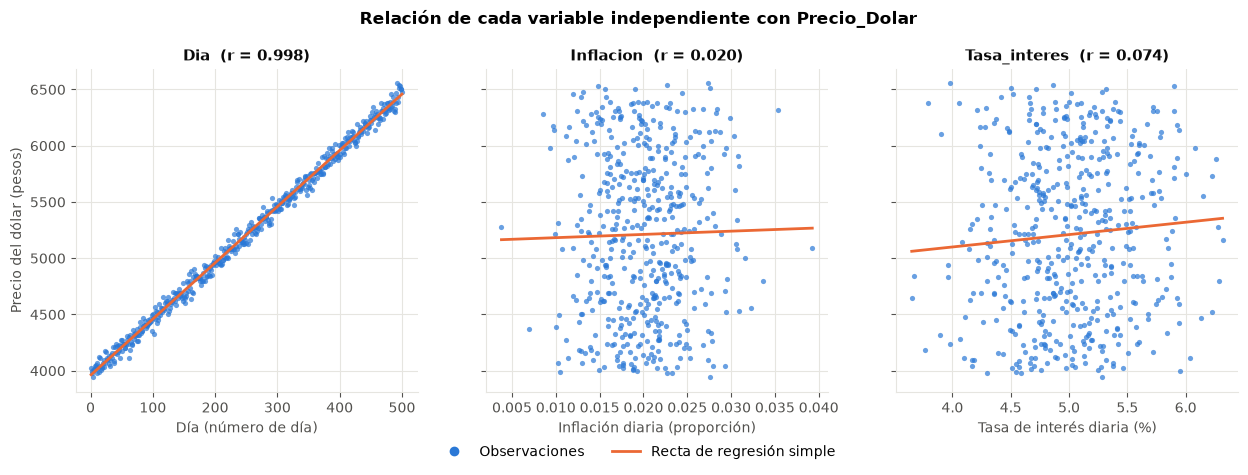

In [9]:
alfa = max(0.15, min(0.7, 600 / len(df)))
fig, ejes = plt.subplots(1, len(VARIABLES), figsize=(15, 4.2), sharey=True)
for ax, var in zip(ejes, VARIABLES):
    ax.scatter(df[var], df[OBJETIVO], s=14, color=AZUL, alpha=alfa, linewidths=0)
    pendiente, corte = np.polyfit(df[var], df[OBJETIVO], 1)
    xs = np.linspace(df[var].min(), df[var].max(), 100)
    ax.plot(xs, pendiente * xs + corte, color=NARANJA, linewidth=2)
    ax.set_title(f"{var}  (r = {df[var].corr(df[OBJETIVO]):.3f})")
    ax.set_xlabel(ETIQUETAS[var])
ejes[0].set_ylabel(ETIQUETAS[OBJETIVO])
fig.legend(handles=[
    Line2D([], [], marker="o", linestyle="", color=AZUL, label="Observaciones"),
    Line2D([], [], color=NARANJA, linewidth=2, label="Recta de regresión simple"),
], loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.08))
fig.suptitle(f"Relación de cada variable independiente con {OBJETIVO}", fontweight="bold", y=1.02)
guardar(fig, "dispersion")
plt.show()

**Lectura de las gráficas de dispersión.** La línea naranja de cada panel es una regresión *simple* (una sola variable), útil para ver la tendencia.

- **Dia:** los puntos forman casi una recta ascendente; es la relación dominante.
- **Inflacion y Tasa_interes:** las nubes de puntos no muestran ningún patrón y las rectas son casi planas: a simple vista estas variables no explican el precio.

## 3. Preparación de los datos

- **Limpieza:** se eliminan nulos y duplicados. En este dataset no hay ninguno, pero el paso se deja en el código para que el proceso sea reproducible con datos nuevos.
- **Atípicos:** se conservan, por las razones explicadas en la sección 2.3.
- **Escalado:** no es necesario. La regresión lineal por mínimos cuadrados da las mismas predicciones con o sin escalar, y sin escalar los coeficientes quedan en las unidades originales, lo que facilita interpretarlos.
- **División:** 80 % para entrenamiento y 20 % para prueba, con `random_state=42` para que el resultado sea reproducible.

**Nota sobre la división.** `Dia` es una variable de tiempo. Al dividir al azar, el modelo se evalúa sobre días que están *en medio* de los días de entrenamiento (interpolación). El enunciado pide un modelo de regresión con división aleatoria, por eso se usa así, pero hay que tener presente que predecir días futuros (más allá del día 500) es una extrapolación y el error puede ser mayor.

In [10]:
# Limpieza: se eliminan nulos y duplicados (si los hubiera) y se verifica el resultado
filas_antes = len(df)
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(f"Filas antes: {filas_antes} | filas después de la limpieza: {len(df)}")

X = df[VARIABLES]
y = df[OBJETIVO]

# División 80 % entrenamiento / 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Filas antes: 500 | filas después de la limpieza: 500
Entrenamiento: (400, 3) | Prueba: (100, 3)


## 4. Modelado

Se ajusta un modelo de **regresión lineal múltiple** con `LinearRegression` de scikit-learn, usando solo los datos de entrenamiento. El modelo busca la ecuación

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_3$$

que minimiza la suma de los errores al cuadrado (mínimos cuadrados ordinarios).

In [11]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

coeficientes = pd.Series(modelo.coef_, index=VARIABLES, name="Coeficiente")
print(f"Intercepto: {modelo.intercept_:,.4f}")
display(coeficientes.to_frame())

ecuacion = f"{OBJETIVO} = {modelo.intercept_:.4f}" + "".join(
    f" {'+' if c >= 0 else '-'} {abs(c):.4f}*{v}" for v, c in coeficientes.items())
print("Ecuación del modelo:")
print(ecuacion)

Intercepto: 3,985.7833


,Coeficiente
Dia,4.9843
Inflacion,-870.7317
Tasa_interes,-1.3774


Ecuación del modelo:
Precio_Dolar = 3985.7833 + 4.9843*Dia - 870.7317*Inflacion - 1.3774*Tasa_interes


## 5. Evaluación

### 5.1 Métricas de desempeño

- **MSE** (error cuadrático medio): promedio de los errores al cuadrado. Cuanto más bajo, mejor.
- **RMSE**: raíz del MSE; queda en las mismas unidades de la variable dependiente.
- **R²** (coeficiente de determinación): proporción de la variación de la variable dependiente que explica el modelo (1 = ajuste perfecto).

Se calculan en entrenamiento y en prueba para detectar un posible sobreajuste.

In [12]:
def calcular_metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_real, y_pred)}


pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)
metricas = {
    "entrenamiento": calcular_metricas(y_train, pred_train),
    "prueba": calcular_metricas(y_test, pred_test),
}
tabla_metricas = pd.DataFrame(metricas).T
print(f"Media de {OBJETIVO}: {y.mean():,.2f} {UNIDAD_Y}")
print(f"RMSE de prueba como % de la media: {100 * metricas['prueba']['RMSE'] / y.mean():.2f} %")
tabla_metricas

Media de Precio_Dolar: 5,211.77 pesos
RMSE de prueba como % de la media: 0.94 %


,MSE,RMSE,R2
entrenamiento,"2,580.4620",50.7982,0.9948
prueba,"2,376.9709",48.7542,0.9963


**Interpretación del desempeño**

| Conjunto | MSE | RMSE | R² |
|---|---|---|---|
| Entrenamiento | 2 580.46 | 50.80 | 0.9948 |
| Prueba | 2 376.97 | 48.75 | 0.9963 |

- **R² = 0.9963 en prueba:** el modelo explica el 99.6 % de la variación del precio del dólar en datos que no vio durante el entrenamiento.
- **MSE = 2 376.97 (pesos²).** Como está en unidades al cuadrado se interpreta mejor con su raíz: **RMSE = 48.75 pesos**, es decir, el modelo se equivoca en promedio unos 49 pesos, menos del 1 % del precio medio (5 212 pesos).
- Las métricas de entrenamiento y prueba son muy parecidas (incluso algo mejores en prueba), así que **no hay sobreajuste**.

### 5.2 Significancia estadística (p-valores)

scikit-learn no calcula p-valores, así que se ajusta el mismo modelo con `statsmodels`. El **p-valor** de un coeficiente indica si su efecto se distingue de cero: si es menor a 0.05 la variable es estadísticamente significativa.

In [13]:
# El mismo modelo ajustado con statsmodels para obtener p-valores e intervalos de confianza
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:           Precio_Dolar   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                 2.504e+04
Date:                Thu, 01 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:58:33   Log-Likelihood:                -2138.7
No. Observations:                 400   AIC:                             4285.
Df Residuals:                     396   BIC:                             4301.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         3985.7833     29.391    135.613   

### 5.3 Coeficientes, p-valores e importancia de las variables

In [14]:
# Coeficiente estandarizado (beta) = coeficiente * desviación estándar de X / desviación estándar de y.
# Al quedar todas las variables en la misma escala, permite comparar su importancia.
ic = ols.conf_int()
betas = coeficientes * X_train.std() / y_train.std()
tabla_coef = pd.DataFrame({
    "Coeficiente": coeficientes,
    "Error estándar": ols.bse[VARIABLES],
    "p-valor": ols.pvalues[VARIABLES],
    "IC 95% inf": ic.loc[VARIABLES, 0],
    "IC 95% sup": ic.loc[VARIABLES, 1],
    "Coef. estandarizado": betas,
    "Efecto de 1 desv. estándar": coeficientes * X_train.std(),
    "Significativa (5%)": np.where(ols.pvalues[VARIABLES] < 0.05, "Sí", "No"),
})
# statsmodels y scikit-learn deben dar los mismos coeficientes
assert np.allclose(ols.params[VARIABLES], modelo.coef_) and np.isclose(ols.params["const"], modelo.intercept_)
print(f"p-valor del intercepto: {ols.pvalues['const']:.3g}")
tabla_coef.style.format({"p-valor": "{:.3g}", "Coeficiente": "{:,.4f}", "Error estándar": "{:,.4f}",
                        "IC 95% inf": "{:,.4f}", "IC 95% sup": "{:,.4f}",
                        "Coef. estandarizado": "{:.4f}", "Efecto de 1 desv. estándar": "{:,.3f}"})

p-valor del intercepto: 0


,Coeficiente,Error estándar,p-valor,IC 95% inf,IC 95% sup,Coef. estandarizado,Efecto de 1 desv. estándar,Significativa (5%)
Dia,4.9843,0.0183,0,4.9484,5.0202,0.9976,700.700,Sí
Inflacion,-870.7317,521.8013,0.096,"-1,896.5788",155.1154,-0.0061,-4.273,No
Tasa_interes,-1.3774,5.3579,0.797,-11.9109,9.1561,-0.0009,-0.661,No


Figura guardada: informe/figuras/dolar_importancia.png


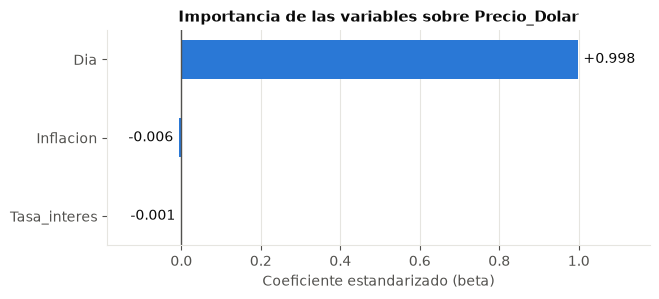

Variable de mayor impacto: Dia


In [15]:
orden = betas.abs().sort_values().index
fig, ax = plt.subplots(figsize=(7, 2.8))
barras = ax.barh(orden, betas[orden], color=AZUL, height=0.5)
ax.bar_label(barras, labels=[f"{v:+.3f}" for v in betas[orden]], padding=4, color=TEXTO)
ax.axvline(0, color=TEXTO_SEC, linewidth=1)
ax.margins(x=0.18)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Coeficiente estandarizado (beta)")
ax.set_title(f"Importancia de las variables sobre {OBJETIVO}")
guardar(fig, "importancia")
plt.show()

print("Variable de mayor impacto:", betas.abs().idxmax())

In [16]:
# Interpretación automática a partir de los resultados obtenidos
UNIDADES_X = {'Dia': 'día', 'Inflacion': 'unidad de inflación (1.0, es decir 100 puntos porcentuales)', 'Tasa_interes': 'punto de tasa de interés'}
for var in VARIABLES:
    c, p = coeficientes[var], ols.pvalues[var]
    sentido = "aumenta" if c > 0 else "disminuye"
    conclusion = "es estadísticamente significativa" if p < 0.05 else "NO es estadísticamente significativa"
    print(f"- {var}: por cada {UNIDADES_X[var]} adicional, {OBJETIVO} {sentido} en promedio "
          f"{abs(c):,.4f} {UNIDAD_Y}, manteniendo constantes las demás variables. "
          f"p-valor {fmt_p(p)}: {conclusion} al 5 %.")

- Dia: por cada día adicional, Precio_Dolar aumenta en promedio 4.9843 pesos, manteniendo constantes las demás variables. p-valor < 0.001: es estadísticamente significativa al 5 %.
- Inflacion: por cada unidad de inflación (1.0, es decir 100 puntos porcentuales) adicional, Precio_Dolar disminuye en promedio 870.7317 pesos, manteniendo constantes las demás variables. p-valor = 0.096: NO es estadísticamente significativa al 5 %.
- Tasa_interes: por cada punto de tasa de interés adicional, Precio_Dolar disminuye en promedio 1.3774 pesos, manteniendo constantes las demás variables. p-valor = 0.797: NO es estadísticamente significativa al 5 %.


**Interpretación de los coeficientes**

Ecuación: `Precio_Dolar = 3985.78 + 4.984·Dia − 870.73·Inflacion − 1.377·Tasa_interes`

- **Intercepto (3 985.78):** precio estimado cuando todas las variables valen cero; es el punto de partida de la recta (cercano al precio del día 1).
- **Dia (+4.984, p < 0.001):** cada día que pasa el dólar sube en promedio **4.98 pesos**, con inflación y tasa constantes. El intervalo de confianza es muy estrecho (4.95 a 5.02). Es la única variable estadísticamente significativa.
- **Inflacion (−870.73, p = 0.096):** el número es grande solo por la escala de la variable (se mueve entre 0.004 y 0.039). Un aumento de 0.01 en la inflación se asocia con una baja de unos 8.7 pesos. Sin embargo, el p-valor es mayor a 0.05 y el intervalo de confianza (−1 896.6 a 155.1) incluye el cero: **no hay evidencia suficiente de que la inflación afecte el precio** en estos datos.
- **Tasa_interes (−1.377, p = 0.797):** un punto más de tasa se asocia con 1.4 pesos menos, pero el efecto **no es significativo**; no se distingue de cero.

**Importancia (coeficientes estandarizados):** `Dia` = 0.998, `Inflacion` = −0.006, `Tasa_interes` = −0.001. Prácticamente todo el poder predictivo del modelo viene de `Dia`: el precio sigue una tendencia en el tiempo y las otras dos variables casi no aportan.

### 5.4 Valores reales vs. predichos

Figura guardada: informe/figuras/dolar_real_vs_predicho.png


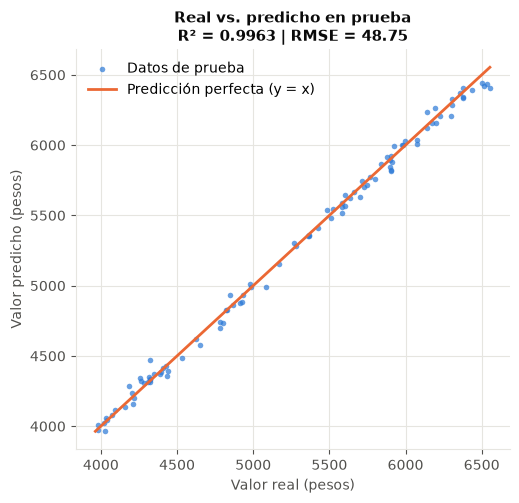

In [17]:
alfa_test = max(0.2, min(0.7, 300 / len(y_test)))
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.scatter(y_test, pred_test, s=16, color=AZUL, alpha=alfa_test, linewidths=0, label="Datos de prueba")
limites = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ax.plot(limites, limites, color=NARANJA, linewidth=2, label="Predicción perfecta (y = x)")
ax.set_xlabel(f"Valor real ({UNIDAD_Y})")
ax.set_ylabel(f"Valor predicho ({UNIDAD_Y})")
ax.set_title(f"Real vs. predicho en prueba\nR² = {metricas['prueba']['R2']:.4f} | RMSE = {metricas['prueba']['RMSE']:.2f}")
ax.legend(loc="upper left")
guardar(fig, "real_vs_predicho")
plt.show()

### 5.5 Análisis de residuos

Figura guardada: informe/figuras/dolar_residuos.png


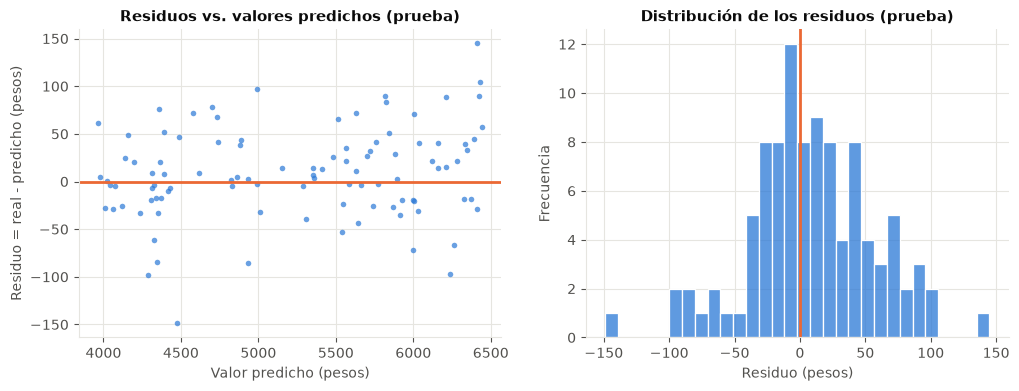

Media de los residuos: 8.826 | Desviación estándar: 48.190


In [18]:
residuos = y_test - pred_test
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.scatter(pred_test, residuos, s=16, color=AZUL, alpha=alfa_test, linewidths=0)
ax1.axhline(0, color=NARANJA, linewidth=2)
ax1.set_xlabel(f"Valor predicho ({UNIDAD_Y})")
ax1.set_ylabel(f"Residuo = real - predicho ({UNIDAD_Y})")
ax1.set_title("Residuos vs. valores predichos (prueba)")
sns.histplot(residuos, bins=30, color=AZUL, edgecolor="white", ax=ax2)
ax2.axvline(0, color=NARANJA, linewidth=2)
ax2.set_xlabel(f"Residuo ({UNIDAD_Y})")
ax2.set_ylabel("Frecuencia")
ax2.set_title("Distribución de los residuos (prueba)")
guardar(fig, "residuos")
plt.show()

print(f"Media de los residuos: {residuos.mean():.3f} | Desviación estándar: {residuos.std():.3f}")

**Lectura de las gráficas de evaluación**

- En *real vs. predicho* los puntos quedan pegados a la diagonal: las predicciones son muy cercanas a los valores reales en todo el rango de precios.
- Los residuos se reparten alrededor de cero sin formar curvas ni embudos, y su histograma es aproximadamente simétrico. Esto indica que la relación lineal es adecuada y que el error es similar en todo el rango.

## 6. Despliegue: exportación del modelo

El modelo entrenado se guarda en disco para usarlo después en la interfaz web sin volver a entrenar. Se exporta en dos formatos:

- **`.pkl` (pickle):** módulo estándar de Python para serializar cualquier objeto.
- **`.joblib` (joblib):** librería recomendada por scikit-learn; es más eficiente con objetos que contienen arreglos grandes de NumPy.

Junto con el modelo se guardan los nombres de las variables, las métricas y los rangos de los datos, que la aplicación usa para validar las entradas.

In [19]:
paquete = {
    "modelo": modelo,
    "ejercicio": "Dólar",
    "variables": VARIABLES,
    "objetivo": OBJETIVO,
    "unidad_objetivo": UNIDAD_Y,
    "etiquetas": ETIQUETAS,
    "intercepto": float(modelo.intercept_),
    "coeficientes": {v: float(c) for v, c in coeficientes.items()},
    "coef_estandarizados": {v: float(b) for v, b in betas.items()},
    "p_valores": {v: float(ols.pvalues[v]) for v in VARIABLES},
    "ic95": {v: [float(ic.loc[v, 0]), float(ic.loc[v, 1])] for v in VARIABLES},
    "ecuacion": ecuacion,
    "metricas": {k: {m: float(x) for m, x in d.items()} for k, d in metricas.items()},
    "rangos": {c: {"min": float(df[c].min()), "max": float(df[c].max()), "media": float(df[c].mean())}
               for c in df.columns},
    "limites_validos": {'Dia': [1, None], 'Inflacion': [0, 1], 'Tasa_interes': [0, 100]},
    "variables_enteras": ['Dia'],
    "n_entrenamiento": len(X_train),
    "n_prueba": len(X_test),
    "random_state": SEMILLA,
    "version_sklearn": sklearn.__version__,
}

ruta_joblib = MODELOS / f"modelo_{NOMBRE}.joblib"
ruta_pkl = MODELOS / f"modelo_{NOMBRE}.pkl"

joblib.dump(paquete, ruta_joblib)              # joblib
with open(ruta_pkl, "wb") as f:                # pickle
    pickle.dump(paquete, f)

# Metadatos legibles (sin el modelo) para el informe
metadatos = {k: v for k, v in paquete.items() if k != "modelo"}
metadatos["correlaciones_objetivo"] = {v: float(corr.loc[v, OBJETIVO]) for v in VARIABLES}
metadatos["atipicos_iqr"] = {c: int(n) for c, n in atipicos.items()}
metadatos["extra"] = {}
with open(MODELOS / f"metadatos_{NOMBRE}.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, indent=2, ensure_ascii=False)

# Comprobación: los modelos cargados predicen igual que el original
cargado_joblib = joblib.load(ruta_joblib)
with open(ruta_pkl, "rb") as f:
    cargado_pkl = pickle.load(f)
assert np.allclose(cargado_joblib["modelo"].predict(X_test), pred_test)
assert np.allclose(cargado_pkl["modelo"].predict(X_test), pred_test)
print("Modelos guardados y verificados:")
for ruta in (ruta_joblib, ruta_pkl):
    print(f"  {ruta.relative_to(BASE)}  ({ruta.stat().st_size} bytes)")

Modelos guardados y verificados:
  modelos/modelo_dolar.joblib  (2132 bytes)
  modelos/modelo_dolar.pkl  (1851 bytes)


In [20]:
# Ejemplo de uso del modelo cargado con valores nuevos
ejemplo = pd.DataFrame([{'Dia': 250, 'Inflacion': 0.02, 'Tasa_interes': 5.0}])
prediccion = cargado_joblib["modelo"].predict(ejemplo[cargado_joblib["variables"]])[0]
print("Entrada:", ejemplo.to_dict("records")[0])
print(f"Predicción de {OBJETIVO}: {prediccion:,.2f} {UNIDAD_Y}")

Entrada: {'Dia': 250, 'Inflacion': 0.02, 'Tasa_interes': 5.0}
Predicción de Precio_Dolar: 5,207.57 pesos


## 7. Conclusiones del ejercicio

1. El modelo lineal predice el precio del dólar con **R² = 0.9963 y RMSE = 48.75 pesos** en prueba (MSE = 2 376.97), un error menor al 1 % del precio medio.
2. **`Dia` es la variable que determina el precio:** cada día el dólar sube en promedio 4.98 pesos (p < 0.001; coeficiente estandarizado 0.998).
3. **`Inflacion` y `Tasa_interes` no resultaron significativas** (p = 0.096 y p = 0.797): con estos datos no se puede afirmar que afecten el precio.
4. No hay sobreajuste: el desempeño en entrenamiento y prueba es casi igual.
5. **Limitación:** el modelo describe una tendencia temporal. Usarlo para días muy posteriores al 500 es extrapolar y supone que la tendencia se mantiene.